# U-Net 脑 MRI 异常区域分割

输入三通道 MRI，输出 FLAIR 异常区域的二值掩膜。本文保留数据、模型、训练、测试与推理主线，具体实现复用仓库模块。

在项目根目录打开，选择安装了 `requirements-notebook.txt` 的 Python 环境。首次运行请先按 [README](README.md) 完成 CLI 数据准备和训练，生成 `outputs/unet256/`；仓库不包含数据和模型权重。默认加载最佳模型、运行完整测试与示例推理，不重新训练。四张图为当前实验的固定快照，已内嵌。

In [1]:
from pathlib import Path
import json
import torch
from torch.utils.data import DataLoader
from IPython.display import display, Markdown

from datasets.mri import MRIDataset, load_manifest, read_pair
from models.unet import UNet
from training.engine import get_device, seed_all, run_epoch

project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "models/unet.py").is_file())
data_root = project_root / "data/kaggle_3m"
run_dir = project_root / "outputs/unet256"
config = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))

torch.set_num_threads(4)
seed_all(config["seed"])
device = get_device("auto")

## 1. 数据与预处理

数据包含 110 位患者、3,929 对 256×256 图像与掩膜。三个通道依次为增强前、FLAIR、增强后序列，部分缺失序列由 FLAIR 替代。按患者划分，避免相邻切片跨集合造成泄漏。

| 集合 | 患者 | 切片 |
| --- | ---: | ---: |
| 训练 | 78 | 2,845 |
| 验证 | 16 | 544 |
| 测试 | 16 | 540 |

`MRIDataset` 对每张图的每个通道执行非零区域 z-score：$\widetilde X=(X-\mu)/\max(\sigma,10^{-6})$，零值背景不变。训练时同步旋转、翻转图像与掩膜；缩放分别用双线性和最近邻插值。

DataLoader 返回图像 $(B,3,H,W)$ 与二值标签 $(B,1,H,W)$。训练集前景仅占约 0.98% 像素，因此后续主要评价前景重叠，不使用像素准确率作为主指标。

In [2]:
manifest = load_manifest(data_root, run_dir / "manifest.json")
datasets = {
    name: MRIDataset(data_root, rows, size=config["size"], augment=name == "train")
    for name, rows in manifest["splits"].items()
}
loaders = {
    name: DataLoader(dataset, batch_size=config["batch_size"], shuffle=name == "train", num_workers=0)
    for name, dataset in datasets.items()
}

**样本：** FLAIR 图像、人工标签与标签叠加；此处不是模型预测。

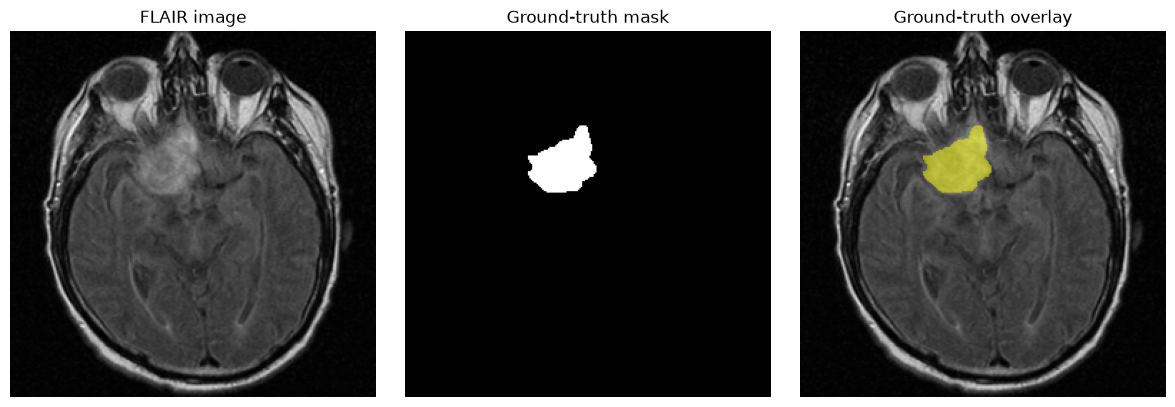

## 2. U-Net

- **编码器：** 两次 `Conv → BatchNorm → ReLU` 提取特征，最大池化将高宽减半。
- **解码器：** 转置卷积将高宽放大两倍，与同尺度编码特征拼接，再用双卷积融合。
- **跳跃连接：** 将编码端的空间细节送回解码端；拼接增加通道数，不改变高宽。

$$D_l=\mathrm{DoubleConv}\left([E_l,\mathrm{Up}(D_{l+1})]\right)$$

最后的 $1\times1$ 卷积输出单通道 logits。实现位于 [models/unet.py](models/unet.py)，这里直接复用并加载最佳权重。

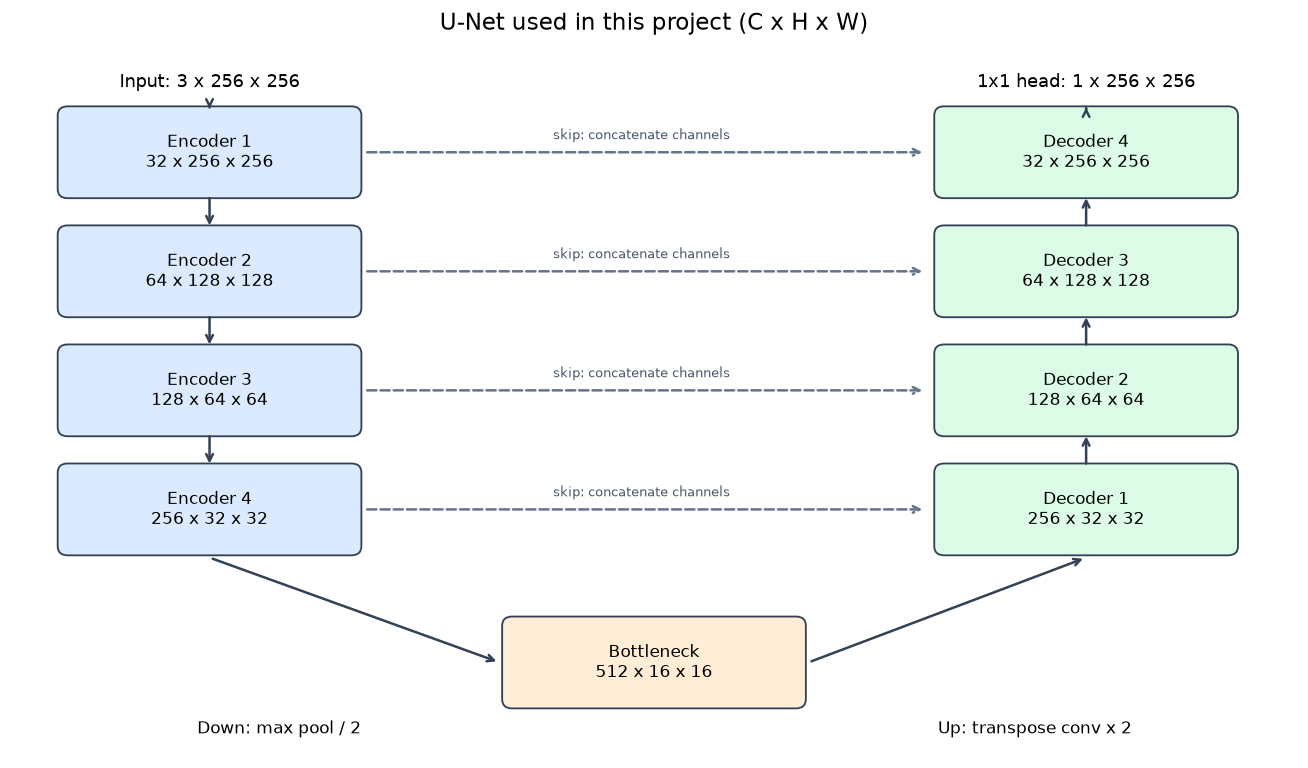

In [3]:
checkpoint = torch.load(run_dir / "best.pt", map_location="cpu", weights_only=True)
assert checkpoint["manifest"] == manifest
assert not checkpoint["config"]["smoke_only"]
assert checkpoint["config"]["size"] == config["size"]

model = UNet(base=checkpoint["config"]["base"]).to(device)
model.load_state_dict(checkpoint["model"])
model.eval();

## 3. 损失与训练

训练使用 BCE 与 soft Dice 的等权组合。对单张切片的概率 $p_i=\sigma(z_i)$ 和标签 $y_i$：

$$\mathcal L_{BCE}=-\frac1N\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]$$
$$\mathcal L_{Dice}=1-\frac{2\sum_i p_i y_i+1}{\sum_i p_i+\sum_i y_i+1},\qquad
\mathcal L=0.5\mathcal L_{BCE}+0.5\mathcal L_{Dice}$$

代码对每张切片计算 Dice 后取批次平均，BCE 直接接收 logits。损失实现见 [training/losses.py](training/losses.py)。

正式训练使用 AdamW（初始学习率 $10^{-3}$）、混合精度、梯度裁剪和早停，按验证患者级 Dice 保存最佳模型。下面可选复用同一训练流程，新实验写入独立目录；如需查看新结果，完成后将 `run_dir` 改为新目录再运行。

In [4]:
RUN_TRAINING = False

if RUN_TRAINING:
    from types import SimpleNamespace
    from training.engine import train

    args = SimpleNamespace(**{
        **config,
        "data": str(data_root),
        "manifest": str(run_dir / "manifest.json"),
        "output": str(project_root / "outputs/notebook_train"),
        "device": str(device),
    })
    train(args, manifest)

当前 `unet256` 实验在第 39 轮早停，第 29 轮最佳，验证患者级 Dice 为 **0.8177**。

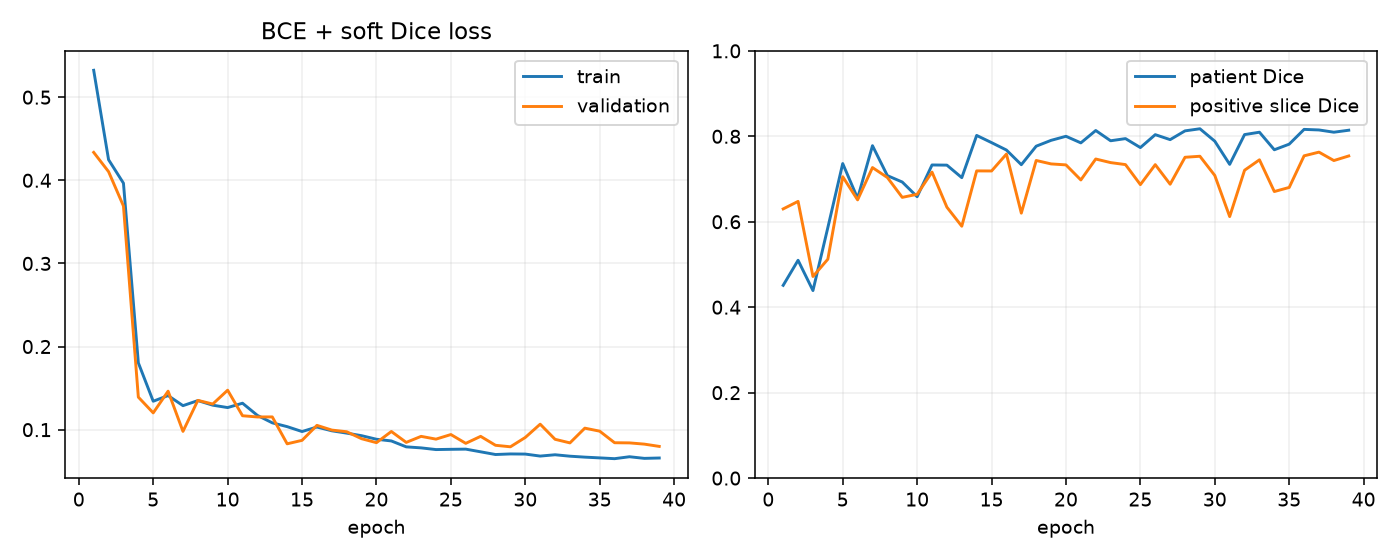

## 4. 测试集评估

预测概率以 0.5 为阈值。设预测前景为 $A$，真实前景为 $G$：

$$Dice=\frac{2|A\cap G|}{|A|+|G|},\qquad IoU=\frac{|A\cap G|}{|A\cup G|}$$

双方都为空时记 1，仅一方为空时记 0。患者级 Dice 先按患者累加所有切片的交集与前景数，再对患者等权平均；正切片 Dice 只统计非空真值。

下面实际运行全部 16 位测试患者的 540 张切片。测试集不参与这次训练的最佳模型选择。

In [5]:
metrics = run_epoch(model, loaders["test"], device)
metric_names = {
    "患者级 Dice": "patient_dice",
    "正切片 Dice": "positive_dice",
    "全部切片 Dice": "dice",
    "全部切片 IoU": "iou",
    "空切片误检率": "empty_false_positive_rate",
}
display(Markdown("| 指标 | 结果 |\n|---|---:|\n" + "\n".join(
    f"| {label} | {metrics[key]:.4f} |" for label, key in metric_names.items()
)))

| 指标 | 结果 |
|---|---:|
| 患者级 Dice | 0.7749 |
| 正切片 Dice | 0.7592 |
| 全部切片 Dice | 0.8792 |
| 全部切片 IoU | 0.8457 |
| 空切片误检率 | 0.0546 |

## 5. 推理与预测效果

取测试集中第一张含前景切片，按相同预处理执行推理：$P=\sigma(f_\theta(X))$，$\hat Y=\mathbf1[P\ge0.5]$。关闭随机增强与梯度记录。

In [6]:
sample_record = next(
    row for row in manifest["splits"]["test"] if read_pair(data_root, row)[1].any()
)
image, target, _ = MRIDataset(data_root, [sample_record], size=config["size"])[0]

with torch.inference_mode():
    probability = model(image.unsqueeze(0).to(device)).sigmoid()[0, 0].cpu()
prediction = probability >= 0.5

下图依次展示：首个被检出的正切片、完全漏检中真实前景最大的切片、空掩膜中误检前景最大的切片。案例有意按类型选择，不代表平均表现。

每行从左到右为原图、真值、预测、误差叠加。绿色为正确前景，红色为误检，青色为漏检。

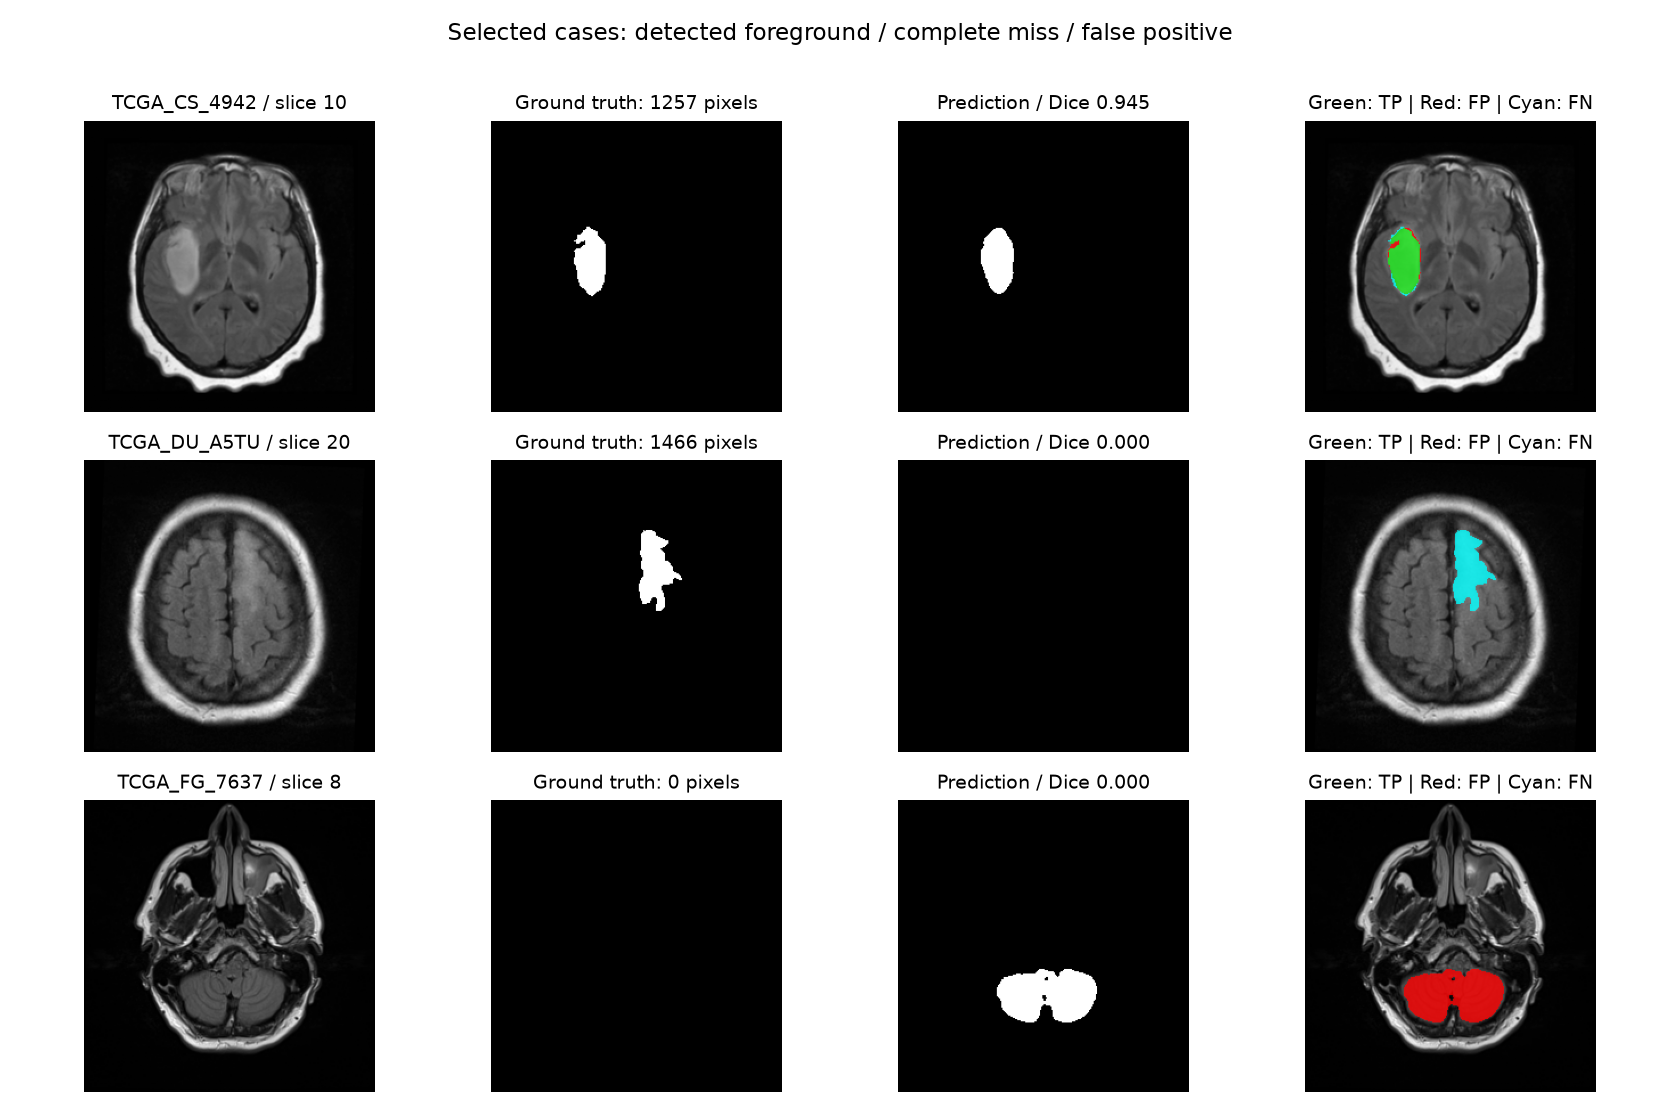

## 6. 结论

当前最佳模型的测试患者级 Dice 为 **0.7749**，正切片 Dice 为 **0.7592**。192 张正切片中有 16 张被全部预测为空，348 张空掩膜中有 19 张出现误检。模型仍存在漏检和误检；这是单次患者划分的研究基线，不能只用全切片平均分判断效果。

参考：[U-Net 原论文](https://arxiv.org/abs/1505.04597) · [数据集](https://www.kaggle.com/datasets/mateuszbuda/lgg-mri-segmentation/data) · [完整操作说明](README.md)